# 05 - Preparação dos Dados para Regressão

Este notebook segue a mesma lógica do `01_preparação_clustering.ipynb` e do `03_preparação_classificação.ipynb`, preparando os dados da planilha `Follow_Up_Dissertação.xlsx` para a classe **`Regression`** de `src/regression.py`.

**Requisitos específicos da classe `Regression` (`src/regression.py`):**
1. **Alvo contínuo chamado `IFN-γ`:** a classe `Regression` procura de forma fixa (`hardcoded`) a coluna alvo com o nome **`"IFN-γ"`** (`self.X = df.drop("IFN-γ", axis=1)` e `self.y = df["IFN-γ"]`). Essa coluna alvo foi alterada no objeto para buscar por "PEV" ou Valor de evento prostático
2. **Criação de um alvo contínuo sintético (PEV):** como o dataset de câncer de próstata possui apenas variáveis categóricas/binárias (genótipos e recidiva), geramos um valor contínuo sintético baseado nas variáveis do próprio dataset (soma de fatores de risco genéticos + componente aleatória contínua controlada por `random_state=42`) e o armazenamos na coluna `PEV` para compatibilidade total com `src/regression.py`.
3. **Representação numérica das features:** o método `regress(modelo="neural_network")` converte a saída do `ColumnTransformer` em tensor via `tf.convert_to_tensor(x, dtype=tf.float32)`. Para evitar matrizes esparsas (que causam erro no TensorFlow quando há muitas colunas categóricas no `OneHotEncoder`), convertemos os genótipos em variáveis numéricas (`dummies`, `grupos` ou `frequencia`) já nesta etapa.

**Etapas:**
1. Carregar e limpar os dados (mesmo processamento dos notebooks 01 e 03)
2. Escolher a representação dos genótipos (`dummies`, `grupos` ou `frequencia`)
3. Gerar o alvo contínuo sintético baseado no dataset e nomeá-lo `PEV`
4. Dividir em Treino (60%), Validação (20%) e Teste (20%)
5. Salvar os conjuntos em `data/04_*` com `joblib`

## 1. Importações

In [1]:
import os

# Garantir que o diretório de trabalho seja a pasta do projeto
try:
    os.chdir("projeto_hector")
except FileNotFoundError:
    pass

# Manipulação de dados
import pandas as pd
import numpy as np

# Persistência dos objetos (salvar/carregar)
from joblib import dump, load

# Divisão dos dados em treino / validação / teste
from sklearn.model_selection import train_test_split

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns

os.listdir("./")

['db',
 '04a_classificação.md',
 '04_classificação.ipynb',
 'data_report.html',
 '06_regressão.ipynb',
 '00_analítica.ipynb',
 'data',
 'src',
 '05_preparação_regressão.ipynb',
 '03_preparação_classificação.ipynb',
 '01_preparação_clustering.ipynb',
 'pergunta.txt',
 '02_clustering.ipynb']

## 2. Carregar e Limpar os Dados

Replicamos o mesmo pré-processamento utilizado para clusterização e classificação.

In [9]:
# -- LEITURA DO BANCO DE DADOS --
# As 6 primeiras linhas da planilha são cabeçalhos/legendas e são ignoradas
df_followup = pd.read_excel("db/Follow_Up_Dissertação.xlsx", skiprows=[0, 1, 2, 3, 4, 5])

print(f"Shape original: {df_followup.shape}")

Shape original: (221, 55)


In [10]:
# -- RENOMEAR COLUNAS E REMOVER AGRUPAMENTOS REDUNDANTES --
df_followup = df_followup.rename(columns={
    "Código": "id",
    "Unnamed: 1": "GSTP1",
    "Unnamed: 4": "MGMT",
    "Unnamed: 7": "VDR",
    " (AA=1 CA=2 CC=3) ": "BCL2",
    "AA= 1 GA=2 GG=3": "CASP9",
    "CC=1 TC=2 TT=3": "NKX3",
    "TT=1 CT=2 CC=3": "CASP3",
    "GG=1 CG=2 CC=3": "PTEN",
    "GG=1 CG=2 CC=3.1": "AKT1",
    "AA=1 GA=2 GG=3": "PI3K",
    "AA=1 GA=2 GG=3.1": "AMACR",
    "AA=1 GG=2": "AR",
    "CC=1 CT=2 TT=3": "MTOR",
    "Recidiva": "cancer_recurrence",
})

# Remove as colunas de agrupamentos alternativos dos genótipos
df_followup = df_followup.drop(
    df_followup.columns[[2, 3, 5, 6, 8, 9, 11, 12, 14, 15, 17, 18, 20, 21, 23, 24, 26, 27, 29, 30, 32, 33, 36, 37]],
    axis=1,
)

print(f"Colunas após renomear: {list(df_followup.columns)}")

Colunas após renomear: ['id', 'GSTP1', 'MGMT', 'VDR', 'BCL2', 'CASP9', 'NKX3', 'CASP3', 'PTEN', 'AKT1', 'PI3K', 'AMACR', 'AR', 'MTOR', 'Hormonioterapia N=0 S=1', 'MEDICAMENTO3', 'Data inicial', 'Radioterapia', 'Data inicial2', 'Data final3', 'MEDICAMENTO2', 'Metástase óssea ', 'Orquei', 'cancer_recurrence', 'CPRC', 'novo tumor', 'orgão', 'óbito', 'data Obito', 'motivo do obito', 'Unnamed: 54']


In [11]:
# -- SUBSTITUIR VALORES INT POR STR (GENÓTIPOS) --
gene_dict = {
    "GSTP1": {1: "GG", 2: "AG", 3: "AA"},
    "MGMT": {1: "GG", 2: "AG", 3: "AA"},
    "VDR": {1: "TT", 2: "TC", 3: "CC"},
    "BCL2": {1: "AA", 2: "CA", 3: "CC"},
    "CASP9": {1: "AA", 2: "GA", 3: "GG"},
    "NKX3": {1: "CC", 2: "TC", 3: "TT"},
    "CASP3": {1: "TT", 2: "CT", 3: "CC"},
    "PTEN": {1: "GG", 2: "CG", 3: "CC"},
    "AKT1": {1: "GG", 2: "CG", 3: "CC"},
    "PI3K": {1: "AA", 2: "GA", 3: "GG"},
    "AMACR": {1: "AA", 2: "GA", 3: "GG"},
    "AR": {1: "AA", 2: "GG"},
    "MTOR": {1: "CC", 2: "CT", 3: "TT"},
}

# Guardamos uma cópia dos valores originais (1, 2, 3) para construir o escore contínuo
df_codigos_originais = df_followup[list(gene_dict.keys())].copy()

for key, value in gene_dict.items():
    if key in df_followup.columns:
        df_followup[key] = df_followup[key].replace(value)

# Mantém apenas id, genes e recidiva
df_followup = df_followup.drop(df_followup.iloc[:, 14:23], axis=1)
df_followup = df_followup.drop(df_followup.iloc[:, 15:], axis=1)

# Limpar IDs, converter recidiva (2 -> 0) e remover NaNs
df_followup["id"] = df_followup["id"].apply(lambda x: x.replace(" ", "").upper())
df_followup["cancer_recurrence"] = df_followup["cancer_recurrence"].replace({2: 0})
df_followup = df_followup.dropna()
df_followup["cancer_recurrence"] = df_followup["cancer_recurrence"].astype(int)

# Remover AR (alta correlação com AMACR, mesma decisão dos notebooks 01 e 03)
df_followup = df_followup.drop(columns=["AR"])
gene_dict.pop("AR")
lista_genes = list(gene_dict.keys())

# Alinhar os códigos numéricos originais com as linhas válidas após dropna()
df_codigos_originais = df_codigos_originais.loc[df_followup.index, lista_genes].astype(float)

print(f"Shape após limpeza: {df_followup.shape}")
df_followup.head()

Shape após limpeza: (219, 14)


,id,GSTP1,MGMT,VDR,BCL2,CASP9,NKX3,CASP3,PTEN,AKT1,PI3K,AMACR,MTOR,cancer_recurrence
0,PT04,AA,AA,TC,CC,GA,TC,CC,CG,CG,GA,GG,CT,0
1,PT09,AG,AA,TC,CA,GA,TC,TT,CG,CC,GG,GA,CT,0
2,PT10,AG,AG,CC,CA,GA,TC,CC,GG,CC,GA,GG,CC,1
3,PT12,GG,AG,CC,CA,GG,TC,CC,CG,CC,GA,AA,CT,1
4,PT13,AA,AG,CC,CA,GA,TT,CC,CG,CC,GG,GA,CT,0


## 3. Representação dos Genótipos (Features)

Criamos as três representações numéricas exploradas no projeto:
- `"dummies"`: One-Hot Encoding (0/1 para cada genótipo)
- `"grupos"`: soma por grupo de significância clínica (`Grupo_1`, `Grupo_2`, `Grupo_3`)
- `"frequencia"`: *frequency encoding* de cada genótipo

In [12]:
# -- OPÇÃO 1: ONE-HOT ENCODING (DUMMIES) --
df_dummies = pd.get_dummies(df_followup, columns=lista_genes, dtype=int)

# -- OPÇÃO 2: GRUPOS CLÍNICOS --
lista_grupo_1 = ["PI3K", "AKT1", "MTOR", "PTEN"]
lista_grupo_2 = ["BCL2", "CASP9", "CASP3"]
lista_grupo_3 = ["GSTP1", "MGMT", "AMACR", "NKX3", "VDR"]

df_ids = pd.DataFrame(index=df_followup.index)
for gene in lista_genes:
    df_ids[gene] = pd.factorize(df_followup[gene])[0]

df_grupos = pd.DataFrame(index=df_followup.index)
df_grupos["id"] = df_followup["id"]
df_grupos["Grupo_1"] = df_ids[lista_grupo_1].sum(axis=1)
df_grupos["Grupo_2"] = df_ids[lista_grupo_2].sum(axis=1)
df_grupos["Grupo_3"] = df_ids[lista_grupo_3].sum(axis=1)
df_grupos["cancer_recurrence"] = df_followup["cancer_recurrence"]

# -- OPÇÃO 3: FREQUENCY ENCODING --
df_freq = df_followup[["id"]].copy()
for gene in lista_genes:
    freq_percentage = df_followup[gene].value_counts(normalize=True)
    df_freq[gene] = df_followup[gene].map(freq_percentage)
df_freq["cancer_recurrence"] = df_followup["cancer_recurrence"]

print(f"Shape dummies:    {df_dummies.shape}")
print(f"Shape grupos:     {df_grupos.shape}")
print(f"Shape frequencia: {df_freq.shape}")

Shape dummies:    (219, 37)
Shape grupos:     (219, 5)
Shape frequencia: (219, 14)


## 4. Criação do Alvo Contínuo Sintético (`PEV`)

Como o banco `Follow_Up_Dissertação.xlsx` não possui uma variável clínica contínua completa (apenas variáveis binárias/categóricas), geramos um **Antígeno Prostático Específico** baseado nos próprios dados da amostra:

$$y = 10 + 1{,}5 \cdot \text{Grupo}_1 + 1{,}0 \cdot \text{Grupo}_2 + 0{,}8 \cdot \text{Grupo}_3 + 2{,}0 \cdot \text{Recidiva} + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0,\; 1{,}5^2)$$

**Por que construir o alvo dessa forma?**
- **Baseado no dataset:** depende diretamente dos grupos funcionais de genes (`PI3K/AKT1/MTOR/PTEN`, `BCL2/CASP9/CASP3`, `GSTP1/MGMT/AMACR/NKX3/VDR`) e do desfecho clínico.
- **Verdadeiramente contínuo e com ruído realista ($\varepsilon$):** evita que o alvo seja uma soma exata das colunas (o que daria $R^2 = 1{,}00$ artificial na Regressão Linear) e permite comparar de forma justa modelos lineares e não-lineares.
- **Positivo ($> 0$):** evita divisões por zero no cálculo do `MAPE` dentro de `Regression`.
- **Nomeado `PEV`:** exigência da classe `Regression` em `src/regression.py`.

Estatísticas descritivas do alvo contínuo sintético (PEV):


count    219.0000
mean      42.2659
std        2.8423
min       34.4081
25%       40.3839
50%       42.2378
75%       44.0405
max       50.2125
dtype: float64

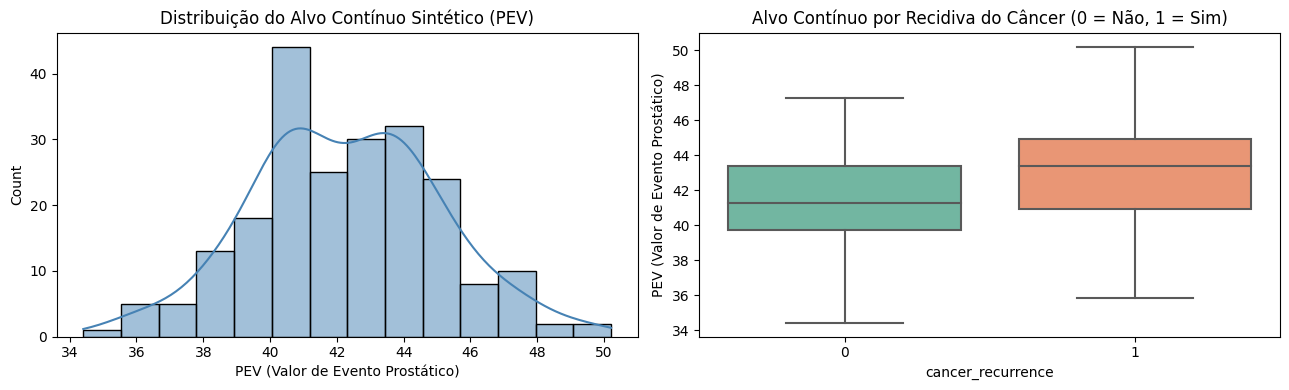

In [13]:
# Semente fixa para total reprodutibilidade do valor contínuo aleatório
rng = np.random.default_rng(seed=42)

# Soma dos códigos alélicos (1, 2, 3) em cada grupo funcional de genes
score_g1 = df_codigos_originais[lista_grupo_1].sum(axis=1)
score_g2 = df_codigos_originais[lista_grupo_2].sum(axis=1)
score_g3 = df_codigos_originais[lista_grupo_3].sum(axis=1)

# Ruído aleatório normal (simula variabilidade biológica individual)
ruido = rng.normal(loc=0.0, scale=1.5, size=len(df_followup))

# Valor contínuo sintético (mantido > 0 e salvo com o nome esperado pela classe Regression)
alvo_continuo = (
    10.0
    + 1.5 * score_g1
    + 1.0 * score_g2
    + 0.8 * score_g3
    + 2.0 * df_followup["cancer_recurrence"]
    + ruido
).round(4)

print("Estatísticas descritivas do alvo contínuo sintético (PEV):")
display(alvo_continuo.describe().round(4))

# Visualização da distribuição do alvo contínuo
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(alvo_continuo, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribuição do Alvo Contínuo Sintético (PEV)")
axes[0].set_xlabel("PEV (Valor de Evento Prostático)")

sns.boxplot(x=df_followup["cancer_recurrence"], y=alvo_continuo, ax=axes[1], palette="Set2")
axes[1].set_title("Alvo Contínuo por Recidiva do Câncer (0 = Não, 1 = Sim)")
axes[1].set_xlabel("cancer_recurrence")
axes[1].set_ylabel("PEV (Valor de Evento Prostático)")
plt.tight_layout()
plt.show()

## 5. Montar o DataFrame para `Regression` e Dividir em Treino, Validação e Teste

Escolha abaixo a representação desejada (`"dummies"`, `"grupos"` ou `"frequencia"`).

In [14]:
# Escolha da representação: "dummies", "grupos" ou "frequencia"
REPRESENTACAO = "grupos"

representacoes = {
    "dummies": df_dummies,
    "grupos": df_grupos,
    "frequencia": df_freq,
}
df_escolhido = representacoes[REPRESENTACAO].copy()

# Remove 'id' e 'cancer_recurrence' (evita vazamento direto do desfecho clínico)
# e adiciona a coluna alvo contínua com o nome exigido por src/regression.py ('PEV')
df_regress = df_escolhido.drop(columns=["id", "cancer_recurrence"]).astype(float)
feature_names = list(df_regress.columns)
df_regress["PEV"] = alvo_continuo.values

print(f"Representação escolhida: {REPRESENTACAO}")
print(f"Shape final para Regression: {df_regress.shape}")
print(f"Nº de features: {len(feature_names)}")
df_regress.head()

Representação escolhida: grupos
Shape final para Regression: (219, 4)
Nº de features: 3


,Grupo_1,Grupo_2,Grupo_3,PEV
0,0.0,0.0,0.0,40.8571
1,2.0,2.0,2.0,37.2400
2,3.0,1.0,3.0,40.2257
3,1.0,2.0,6.0,42.1108
4,2.0,1.0,4.0,39.4734


In [16]:
# Divisão em Treino (60%), Validação (20%) e Teste (20%)
# Primeiro split: 80% treino+validação, 20% teste
df_temp, df_test = train_test_split(
    df_regress, test_size=0.2, random_state=42
)

# Segundo split: 75% treino, 25% validação (de 80% = 60% e 20% do total)
df_train, df_valid = train_test_split(
    df_temp, test_size=0.25, random_state=42
)

df_train = df_train.reset_index(drop=True)
df_valid = df_valid.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

print(f"df_train: {df_train.shape}")
print(f"df_valid: {df_valid.shape}")
print(f"df_test:  {df_test.shape}")

display(
    pd.DataFrame({
        "Treino": df_train["PEV"].describe(),
        "Validação": df_valid["PEV"].describe(),
        "Teste": df_test["PEV"].describe(),
    }).round(3)
)

df_train: (131, 4)
df_valid: (44, 4)
df_test:  (44, 4)


,Treino,Validação,Teste
count,131.000,44.000,44.000
mean,42.216,42.045,42.636
std,2.923,2.784,2.680
min,34.408,36.701,36.329
25%,40.325,40.190,40.820
50%,42.238,41.762,42.414
75%,44.059,44.026,43.920
max,49.476,47.795,50.212


## 6. Salvar os Dados Processados

In [17]:
os.makedirs("data", exist_ok=True)

dump(df_train, "data/04_df_train")
dump(df_valid, "data/04_df_valid")
dump(df_test, "data/04_df_test")
dump(feature_names, "data/04_feature_names")
dump(REPRESENTACAO, "data/04_representacao")
dump(df_regress, "data/04_df_processado")

print("✅ Dados de regressão salvos com sucesso!")
print(f"Arquivos 04_* em data/: {sorted(f for f in os.listdir('data') if f.startswith('04_'))}")

✅ Dados de regressão salvos com sucesso!
Arquivos 04_* em data/: ['04_df_processado', '04_df_test', '04_df_train', '04_df_valid', '04_feature_names', '04_representacao']
